# Predicting ATP match win probabilities beyond rankings

**Data foundations · 2015–2025 ATP men's singles**

The executed cells establish the ranking benchmark, inspect training data and verify a surface-history example from the Cincinnati final. The [research plan](docs/project-plan.zh.md) describes the upcoming four-group experiment and final evaluation. Reproduction instructions are in the [README](README.md).

## 1. Predictive task

At the start of a tournament, predict which of two players would win a given singles match, conditional on both playing and completing it. The inputs must already be observable at that time. The prediction target is whether player A wins. The data preparation code assigns the lexicographically smaller player ID to A before constructing features. Each match has one A/B orientation.

How well can we estimate A's pre-match win probability, and what do recent overall form, same-surface performance and prior head-to-head meetings add beyond rankings? A simple reference rule predicts the better-ranked player. Rank-only logistic regression will provide the probability baseline.

## 2. Exploratory analysis, data collection and preprocessing

TennisMyLife distributes annual ATP match files with tournament start weeks, surfaces, player identities, rankings and results. The project covers main-draw singles at Grand Slams, Masters and tour-level events on hard, clay or grass courts. The shared loader in `scripts/baseline.py` checks identity, rankings and score eligibility and reports the first reason for each exclusion. Season counts below describe coverage. Only the training seasons contribute outcomes to the first figure. [Dataset and field descriptions](https://stats.tennismylife.org/tennis-match-database)

In [1]:
from bisect import bisect_left
from collections import Counter
from datetime import timedelta
from math import isclose, log

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

from scripts.baseline import load_matches, ranking_result, split_name
from scripts.prepare_data import build_model_rows

matches, audit = load_matches()
train = [match for match in matches if split_name(match["season"]) == "train"]
validation = [match for match in matches if split_name(match["season"]) == "validation"]
split_counts = Counter(split_name(match["season"]) for match in matches)

print("Eligible matches by season group")
for group, seasons in (("warmup", "2015"), ("train", "2016–2022"),
                       ("validation", "2023"), ("test", "2024–2025")):
    print(f"  {seasons:10} {group:12} {split_counts[group]:>7,}")

totals = Counter()
for season_counts in audit.values():
    totals.update(season_counts)
print(f"\nCleaning audit across all files: {totals['raw']:,} rows read")
for key, label in (("level", "Event level"), ("surface", "Surface"),
                   ("player_id", "Player identity"), ("ranking", "Ranking"),
                   ("score", "Score"), ("duplicate", "Duplicate draw row"),
                   ("spurious", "Spurious draw row")):
    print(f"  Excluded · {label:16} {totals[key]:>7,}")
print(f"  Eligible                    {totals['eligible']:>7,}")

Eligible matches by season group
  2015       warmup         2,507
  2016–2022  train         16,186
  2023       validation     2,588
  2024–2025  test           5,088

Cleaning audit across all files: 30,716 rows read
  Excluded · Event level        3,303
  Excluded · Surface                0
  Excluded · Player identity        0
  Excluded · Ranking               70
  Excluded · Score                971
  Excluded · Duplicate draw row       2
  Excluded · Spurious draw row       1
  Eligible                     26,369


### How often does the better-ranked player win?

Group training matches by the absolute difference between the opponents' rankings. The dashed line marks a 50% win rate. Labels give the win rate and the number of matches in each bin. Equal rankings have no favorite under this rule.

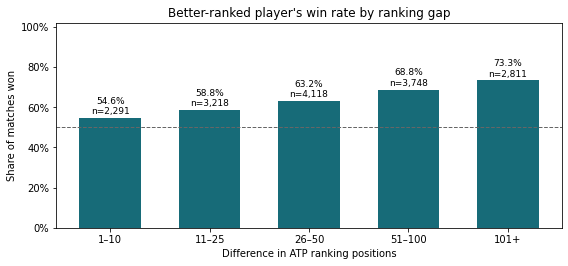

In [2]:
gap_limits = [10, 25, 50, 100]
gap_labels = ["1–10", "11–25", "26–50", "51–100", "101+"]
gap_groups = [[] for label in gap_labels]
for match in train:
    gap = abs(match["winner_rank"] - match["loser_rank"])
    if gap > 0:
        gap_groups[bisect_left(gap_limits, gap)].append(match)

gap_results = [ranking_result(group) for group in gap_groups]
win_rates = [correct / count for correct, count in gap_results]

fig, ax = plt.subplots(figsize=(8, 3.8))
bars = ax.bar(gap_labels, win_rates, color="#176B78", width=0.62)
ax.axhline(0.5, color="#666666", linewidth=1, linestyle="--")
for bar, rate, (_, count) in zip(bars, win_rates, gap_results):
    ax.text(bar.get_x() + bar.get_width() / 2, rate + 0.02,
            f"{rate:.1%}\nn={count:,}", ha="center", fontsize=9)
ax.set(title="Better-ranked player's win rate by ranking gap",
       xlabel="Difference in ATP ranking positions", ylabel="Share of matches won",
       ylim=(0, 1.02))
ax.yaxis.set_major_formatter(PercentFormatter(1))
fig.tight_layout()
plt.show()

For a gap of 1–10 places, the favorite won 54.6% of training matches. For a gap of 101 or more places, the rate was 73.3%. Ranking therefore supplies a meaningful starting point, especially when the players are far apart.

### How much same-surface history is available before a tournament?

Count eligible prior matches for each player appearing in each training match. History can draw on the 2015 warm-up season and earlier training matches. For a tournament starting on date $d$, count starts from $d-364$ through $d-21$ days, inclusive. The three-week buffer handles the fact that every round in an event shares its start week.

Each player appearance contributes once, so a player competing in several matches contributes several observations. Percentages are calculated within each surface.

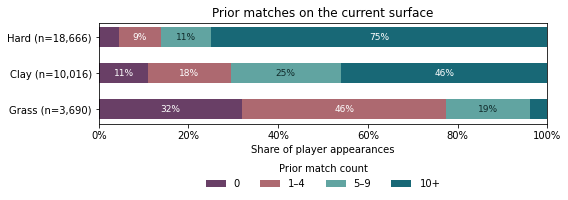

Hard: 2,580 of 18,666 appearances had fewer than five prior matches (13.8%).
Clay: 2,942 of 10,016 appearances had fewer than five prior matches (29.4%).
Grass: 2,859 of 3,690 appearances had fewer than five prior matches (77.5%).


In [3]:
model_rows = build_model_rows(matches)
surfaces = ["Hard", "Clay", "Grass"]
coverage_labels = ["0", "1–4", "5–9", "10+"]
coverage = {surface: Counter() for surface in surfaces}
for row in model_rows:
    if row["split"] == "train":
        for history_count in (row["surface_matches_a"], row["surface_matches_b"]):
            bucket = bisect_left([0, 4, 9], history_count)
            coverage[row["surface"]][bucket] += 1

counts = [sum(coverage[surface].values()) for surface in surfaces]
assert sum(counts) == 2 * len(train)
colors = ["#693F66", "#AD6970", "#61A4A1", "#186876"]
fig, ax = plt.subplots(figsize=(8, 3.2))
left = [0.0] * len(surfaces)
for bucket, (label, color) in enumerate(zip(coverage_labels, colors)):
    shares = [coverage[surface][bucket] / n for surface, n in zip(surfaces, counts)]
    ax.barh(surfaces, shares, left=left, height=0.55, label=label, color=color)
    for i, share in enumerate(shares):
        if share >= 0.08:
            ax.text(left[i] + share / 2, i, f"{share:.0%}", ha="center",
                    va="center", color="white" if bucket != 2 else "#102B2B", fontsize=9)
    left = [a + b for a, b in zip(left, shares)]
ax.set_yticks(range(len(surfaces)))
ax.set_yticklabels([f"{s} (n={n:,})" for s, n in zip(surfaces, counts)])
ax.invert_yaxis()
ax.set(title="Prior matches on the current surface", xlabel="Share of player appearances",
       xlim=(0, 1))
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.legend(title="Prior match count", ncol=4, loc="upper center",
          bbox_to_anchor=(0.5, -0.31), frameon=False)
fig.tight_layout()
plt.show()

for surface, n in zip(surfaces, counts):
    sparse = coverage[surface][0] + coverage[surface][1]
    print(f"{surface}: {sparse:,} of {n:,} appearances had fewer than five prior matches ({sparse/n:.1%}).")

Grass has the sparsest history: 77.5% of training appearances have fewer than five eligible prior grass matches under this window. The corresponding shares are 29.4% on clay and 13.8% on hard courts. This motivates shrinking small-sample win rates toward 0.5 before comparing the models.

### Data foundations and one verified match

The prepared table has one row per training or validation **match**. Each player's intermediate count measures prior **matches on the current surface**. The CLI writes the same rows to `data/processed/model_input.csv`. Player IDs, names, split and dates identify the observation. The two candidate numerical inputs are `log_rank_diff = log(rank_B) − log(rank_A)` and `surface_rate_diff = rate_A − rate_B`. Positive values favor A. The observed label `a_won` is stored separately from these inputs. See the [published feature CSV](data/processed/model_input.csv), [processing guide](docs/data-processing.md), [column definitions](docs/data.md) and [outcome rules](docs/outcomes.md) for details.

In [4]:
prepared_counts = Counter(row["split"] for row in model_rows)
assert prepared_counts == {"train": len(train), "validation": len(validation)}
assert len({row["match_id"] for row in model_rows}) == len(model_rows)
print(f"{len(model_rows):,} unique matches · "
      f"{prepared_counts['train']:,} training + {prepared_counts['validation']:,} validation")

18,774 unique matches · 16,186 training + 2,588 validation


**Cincinnati final, 2023 · Carlos Alcaraz vs. Novak Djokovic.** Replay one validation observation directly from the cleaned source matches. The reference scan below rebuilds each player's eligible hard-court history and checks the stored counts, wins, smoothed rate and latest contributing tournament week. The players are identified by ID. The dates refer to tournament starts, including the start used as this prediction's cutoff.

In [5]:
example = next(row for row in model_rows if row["match_id"] == "2023-422:55")
source = next(m for m in validation
              if (m["tourney_id"], m["match_num"]) == (example["tourney_id"], example["match_num"]))
expected_ids = sorted([source["winner_id"], source["loser_id"]])
assert expected_ids == [example["player_a_id"], example["player_b_id"]]

start = source["tourney_date"]
window_start, window_end = start - timedelta(weeks=52), start - timedelta(days=21)
print(f"{example['surface']} court · tournament starts {start}")
print(f"Eligible prior tournament starts: {window_start} through {window_end} (inclusive)")

for side in ("a", "b"):
    player_id = example[f"player_{side}_id"]
    history = [m for m in matches
               if m["surface"] == source["surface"]
               and window_start <= m["tourney_date"] <= window_end
               and player_id in (m["winner_id"], m["loser_id"])]
    wins = sum(m["winner_id"] == player_id for m in history)
    count = len(history)
    rate = (wins + 1) / (count + 2)
    latest = max(m["tourney_date"] for m in history).isoformat()

    assert (count, wins, latest) == (example[f"surface_matches_{side}"],
                                     example[f"surface_wins_{side}"],
                                     example[f"latest_history_date_{side}"])
    assert isclose(rate, example[f"surface_rate_{side}"])
    name = example[f"player_{side}_name"]
    rank = example[f"rank_{side}"]
    print(f"{side.upper()}  {name} ({player_id}), rank {rank}: {wins}/{count} wins, "
          f"smoothed {(wins + 1)}/{(count + 2)} = {rate:.1%}, latest start {latest}")

assert isclose(log(example["rank_b"]) - log(example["rank_a"]), example["log_rank_diff"])
assert isclose(example["surface_rate_a"] - example["surface_rate_b"], example["surface_rate_diff"])
print(f"Inputs: log-rank difference {example['log_rank_diff']:+.3f}, "
      f"surface-rate difference {100 * example['surface_rate_diff']:+.1f} percentage points")

Hard court · tournament starts 2023-08-14
Eligible prior tournament starts: 2022-08-15 through 2023-07-24 (inclusive)
A  Carlos Alcaraz (A0E2), rank 1: 22/26 wins, smoothed 23/28 = 82.1%, latest start 2023-03-20
B  Novak Djokovic (D643), rank 2: 27/29 wins, smoothed 28/31 = 90.3%, latest start 2023-02-27
Inputs: log-rank difference +0.693, surface-rate difference -8.2 percentage points


In [6]:
# Reveal the recorded target only after checking the pre-tournament inputs.
assert example["a_won"] == int(source["winner_id"] == example["player_a_id"])
print(f"Observed outcome: {source['winner_name']} won. Target a_won = {example['a_won']}.")

Observed outcome: Novak Djokovic won. Target a_won = 0.


Alcaraz had the better ranking. Djokovic had the higher historical hard-court win rate under the chosen window. The model comparison will measure how often that additional information helps across matches.

## 3. Modeling

**Implemented.** Eight ranking-containing logistic subsets, an overall Elo baseline and the extended historical-strength models have now been fitted and scored. The complete executed comparison, feature ablations and frozen choice appear in the appended **Modeling and validation: frozen extended experiment** section and in [modeling.ipynb](modeling.ipynb).

The original [four-feature table](data/processed/model_features.csv) supplies the prescribed comparisons. All probability models use the [shared scoring function](scripts/metrics.py) and the same 2,588 validation matches.

## 4. Evaluation

The foundation ranking-rule result is retained below. The appended modeling section reports all probability-model scores on the same eligible 2023 rows. The course's eight-feature-subset winner is selected by 2023 log loss; the advanced recommendation was frozen using training-period forward folds before 2023 scoring. Accuracy is a secondary metric. **Final evaluation on 2024–2025 remains pending.**

In [7]:
correct, scored = ranking_result(validation)
print("2023 validation · pick the better-ranked player")
print(f"Correct picks: {correct:,} / {scored:,} ({correct / scored:.2%})")
print(f"Equal-ranking matches without a pick: {len(validation) - scored:,}")

2023 validation · pick the better-ranked player
Correct picks: 1,640 / 2,588 (63.37%)
Equal-ranking matches without a pick: 0


**How to read the metrics.** Accuracy counts correct winner picks. Log loss also measures confidence. For example, if A wins, assigning A a hypothetical 0.80 chance incurs a loss of $-\log(0.8)\approx0.223$, while assigning A a 0.20 chance incurs about 1.609. Lower average log loss is better.

**Pending final evaluation.** Score the frozen models on exactly the same eligible matches from 2024 and 2025. Report sample counts, accuracy and changes in percentage points, plus log loss for each probability model. Compare the two test seasons separately and combined. Plot mean predicted and observed win rates for groups of similar predictions, labeling each group with its match count. Use the full test set to support the conclusion and one match to illustrate it.

## 5. Discussion of related work

Kovalchik compares ranking-based and other methods for predicting professional tennis matches. This motivates measuring how much a ranking rule already explains. [Kovalchik (2016)](https://doi.org/10.1515/jqas-2015-0059)

Vaughan Williams and coauthors study Elo ratings and tennis forecasts. Their treatment of court surfaces gives a comparison for our simpler historical win-rate feature, which does not adjust wins for opponent strength. [Vaughan Williams et al. (2021)](https://doi.org/10.1515/jqas-2019-0110)

**Pending after evaluation.** Compare the direction and scale of our observed effect with the papers' findings. Identify differences in seasons, player populations and predictors that affect the interpretation.

<!-- frozen-modeling-results -->
# Modeling and validation: frozen extended experiment

These saved results extend the prescribed eight ranking/history models with past-only strength, form and technical statistics. All numeric comparisons below use identical 2023 matches. The foundation notebook's original code and saved outputs are preserved. The final test seasons remain unopened.

## Decision and measured improvement

The advanced recommendation is **`oof_convex_ensemble`**, frozen using training-period forward folds before scoring 2023.
On the same **2,588 validation matches**, its log loss is **0.61153**, compared with **0.62980** for rank-only logistic regression.
That is an absolute log-loss reduction of **0.01826** (2.90% relative).
Accuracy changes from **63.37%** to **65.07%** (+1.70 percentage points).
The deterministic ranking rule achieves **63.37%** and has no probability log-loss score.

The paired tournament-start-date bootstrap interval for the log-loss reduction is **[0.01233, 0.02458]**.
This is a conditional, exploratory interval: it does not account for the model search, dependence across dates or future-season drift.

The lowest saved 2023 log loss belongs to **`all_history_reference_C0.01`**. This is a descriptive validation result, distinct from the pre-2023 advanced recommendation.
The course's eight-subset protocol selects **`lr_101_C0.01`** on 2023.
**No 2024–2025 test result has been computed; state-of-the-art superiority is not established.**

,model,description,selection_role,matches,mean_log_loss,accuracy,brier,training_period_cv_log_loss
0,all_history_reference_C0.01,all history reference C0.01,Diagnostic comparison,2588,0.61056,0.65263,0.21220,0.61329
1,history_linear_C0.01,history linear C0.01,Diagnostic comparison,2588,0.61056,0.65263,0.21220,0.61329
2,oof_convex_ensemble,Temporal OOF ensemble,Advanced recommendation frozen before 2023,2588,0.61153,0.65070,0.21241,NaN
3,without_rank_C0.01,without rank C0.01,Diagnostic comparison,2588,0.61342,0.65340,0.21332,0.61348
4,hist_l15_reg50,hist l15 reg50,Diagnostic comparison,2588,0.61455,0.65417,0.21345,0.61409
5,without_serve_C0.01,without serve C0.01,Diagnostic comparison,2588,0.61505,0.64335,0.21420,0.61414
6,cat_d3_half3.0,cat d3 half3.0,Diagnostic comparison,2588,0.61548,0.64954,0.21400,0.61394
7,without_elo_C0.1,without elo C0.1,Diagnostic comparison,2588,0.61916,0.64992,0.21581,0.61704
8,lr_101_C0.01,Rank + form + H2H,8-subset winner selected on 2023,2588,0.62891,0.63447,0.21980,0.62502
9,lr_100_C0.01,Rank + form,Diagnostic comparison,2588,0.62920,0.63524,0.21992,0.62623


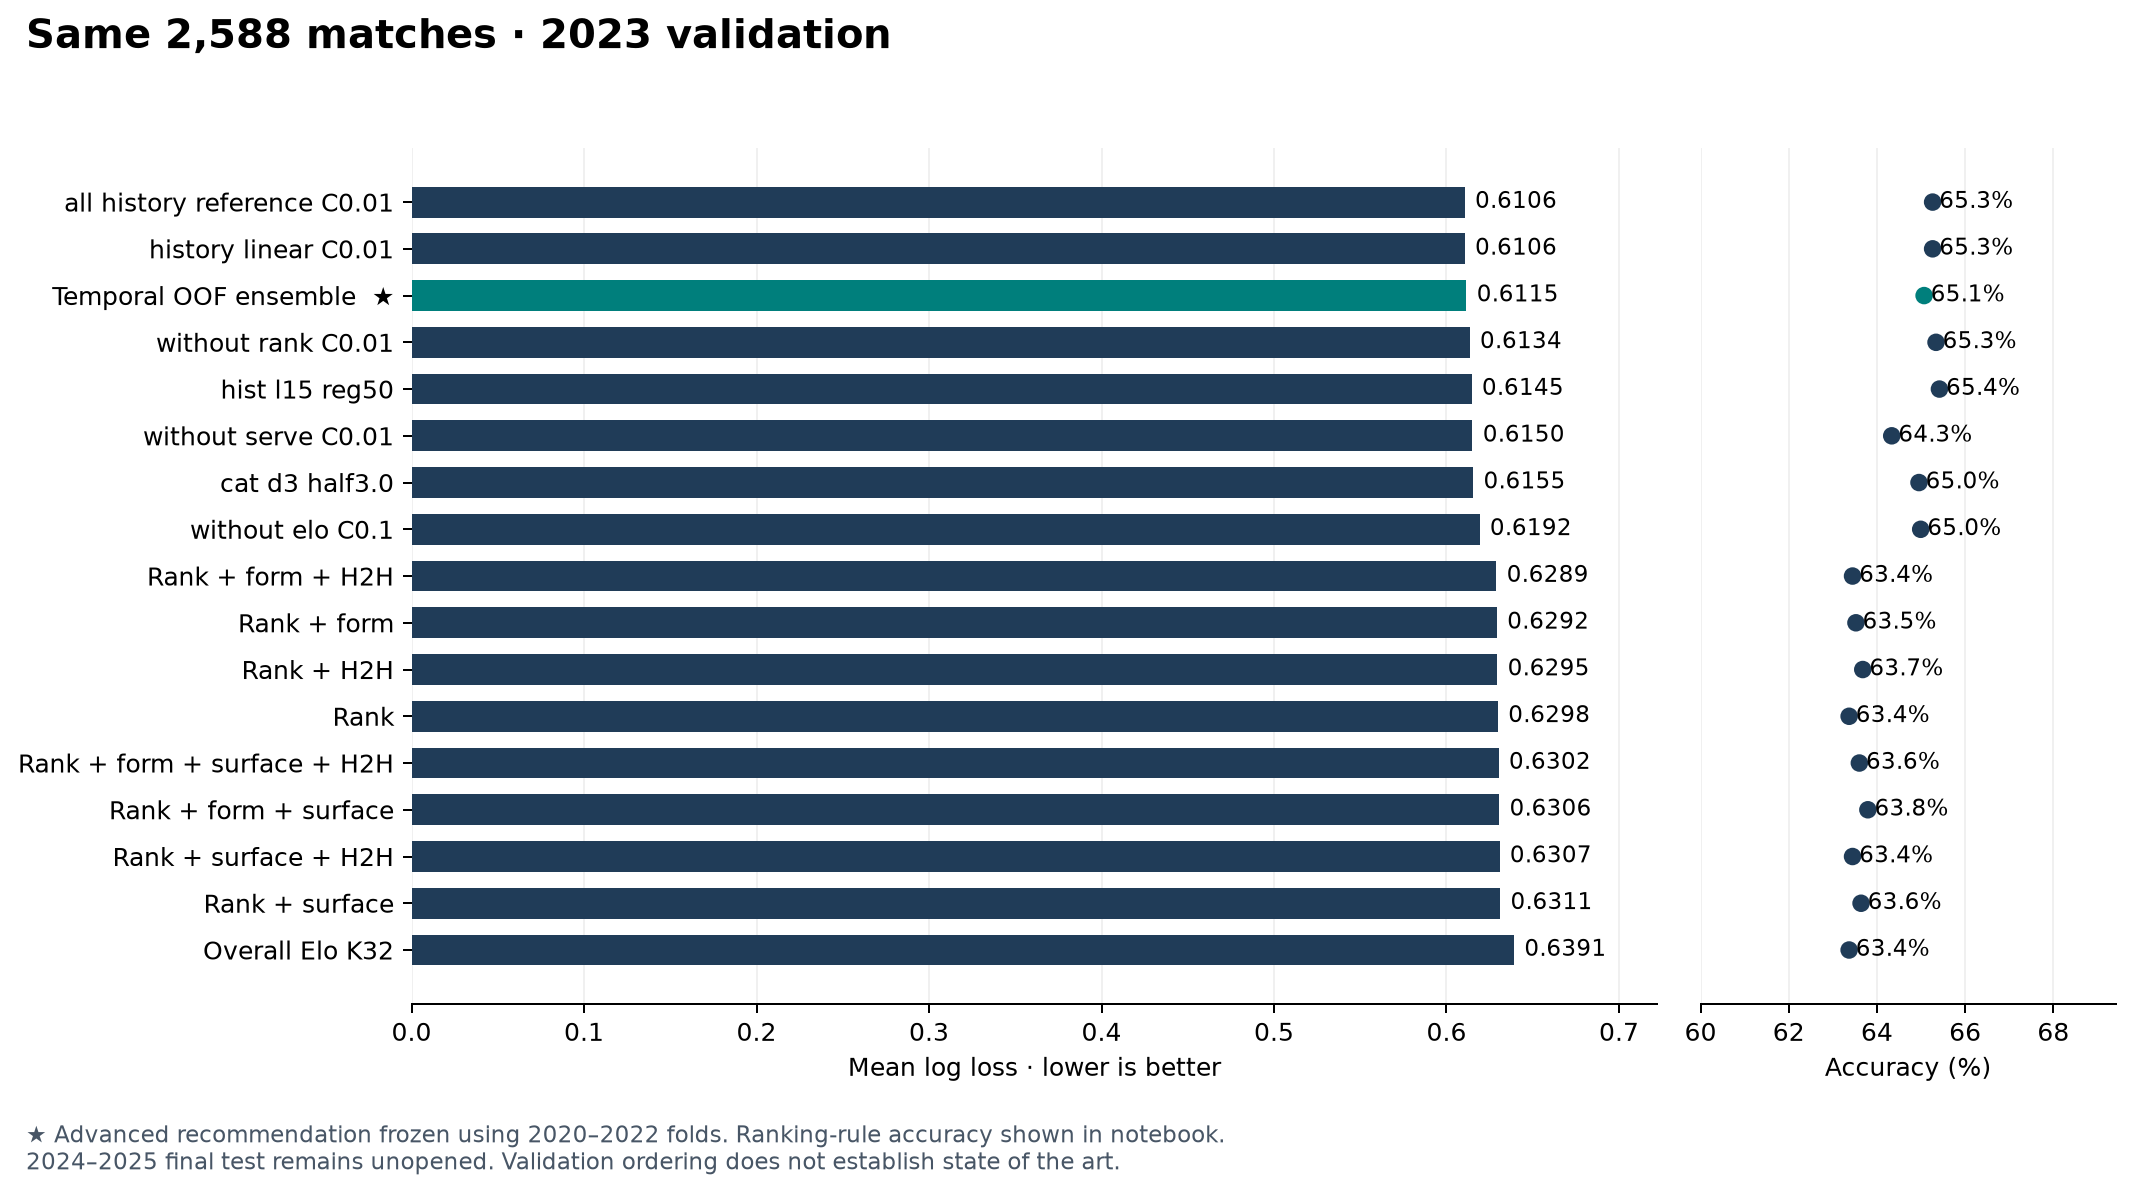

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
from scripts.model_report import (load_results, comparison_table, subset_contributions, advanced_diagnostics, subgroup_table, worked_match, ROOT)
report = load_results(ROOT / 'results' / 'modeling')
pd.set_option('display.max_columns', None)
pd.set_option('display.precision', 5)
display(comparison_table(report))
display(Image(filename=str(ROOT / 'results/modeling/model_comparison.png')))

## Temporal validation and the frozen choice

Candidates are tuned on expanding forward folds for 2020, 2021 and 2022. Each fit uses only earlier rows available by the first fold date minus 21 days. The advanced family winners and ensemble choice are written before 2023 scoring. For the blend gate, family configurations and weights are chosen using only 2020–2021 predictions, then compared on 2022. After selecting the blend procedure, family configurations and weights are refitted using all three development folds. Ensemble weights fitted to pooled out-of-fold predictions have a meta-training loss, which must not be called an unbiased CV estimate. All models are symmetric under exchanging A and B. Historical result features use the same T−21 cutoff.

In [2]:
selected_names = list(report['frozen']['selected_by_family'].values())
display(report['cv'][report['cv'].name.isin(selected_names)].sort_values('mean_log_loss'))
display(pd.DataFrame({'component': report['frozen']['ensemble_components'], 'weight': report['frozen']['ensemble_weights']}))
print('Advanced recommendation:', report['frozen']['advanced_champion'])
print('2022 blend gate:', report['frozen']['ensemble_gate_2022'])

,name,family,mean_log_loss,2020,2021,2022
36,history_linear_C0.01,advanced_linear,0.61329,0.61549,0.62108,0.60488
60,all_history_reference_C0.01,all_history_reference,0.61329,0.61549,0.62108,0.60488
69,without_rank_C0.01,without_rank,0.61348,0.61401,0.62109,0.60603
49,cat_d3_half3.0,catboost,0.61394,0.61760,0.62018,0.60629
58,hist_l15_reg50,histboost,0.61409,0.61315,0.62281,0.60630
66,without_serve_C0.01,without_serve,0.61414,0.61785,0.61879,0.60797
64,without_elo_C0.1,without_elo,0.61704,0.61691,0.62198,0.61243
29,lr_111_C0.1,lr_111,0.62252,0.62358,0.62354,0.62106
13,lr_011_C0.1,lr_011,0.62340,0.62311,0.62486,0.62216
24,lr_110_C0.01,lr_110,0.62356,0.62413,0.62391,0.62295


,component,weight
0,history_linear_C0.01,0.50928
1,cat_d3_half3.0,0.15236
2,hist_l15_reg50,0.31840
3,raw_elo_k32_diff,0.01995


Advanced recommendation: oof_convex_ensemble
2022 blend gate: True


## What does history add?

The first table removes one history group from the original four-feature logistic model. Positive loss increases mean removing that information worsened validation predictions, conditional on the other features. These are predictive comparisons, not causal effects; correlated features can substitute for each other. Each subset's regularization was chosen within training years.

The extended linear diagnostics remove explicit Elo rating features, technical statistics or ranking information from the all-history linear reference. `without_elo` retains form residuals calculated against Elo expected wins, so it does not remove all Elo-derived information. Regularization is retuned independently under the same three-value grid. Do not attribute a nonlinear champion's gain to a single feature from these diagnostics.

In [3]:
display(subset_contributions(report))
display(advanced_diagnostics(report))

,removed_from_four_feature_model,full_model_log_loss,reduced_model_log_loss,loss_increase_when_removed,reduced_model
0,Recent overall form,0.63021,0.63073,0.00053,lr_011_C0.1
1,Same-surface results,0.63021,0.62891,-0.00130,lr_101_C0.01
2,Head-to-head history,0.63021,0.63056,0.00035,lr_110_C0.01


,model,description,selection_role,matches,mean_log_loss,accuracy,brier,training_period_cv_log_loss,loss_increase_vs_full_linear_reference
0,all_history_reference_C0.01,all history reference C0.01,Diagnostic comparison,2588,0.61056,0.65263,0.21220,0.61329,0.00000
1,without_elo_C0.1,without elo C0.1,Diagnostic comparison,2588,0.61916,0.64992,0.21581,0.61704,0.00860
2,without_serve_C0.01,without serve C0.01,Diagnostic comparison,2588,0.61505,0.64335,0.21420,0.61414,0.00449
3,without_rank_C0.01,without rank C0.01,Diagnostic comparison,2588,0.61342,0.65340,0.21332,0.61348,0.00286


## Probability reliability and difficult matches

Calibration uses fixed-width probability bins and displays counts. Subgroups are descriptive checks on the same validation season, not additional tuning folds. Grass and close-ranking subsets have fewer matches and more uncertainty.

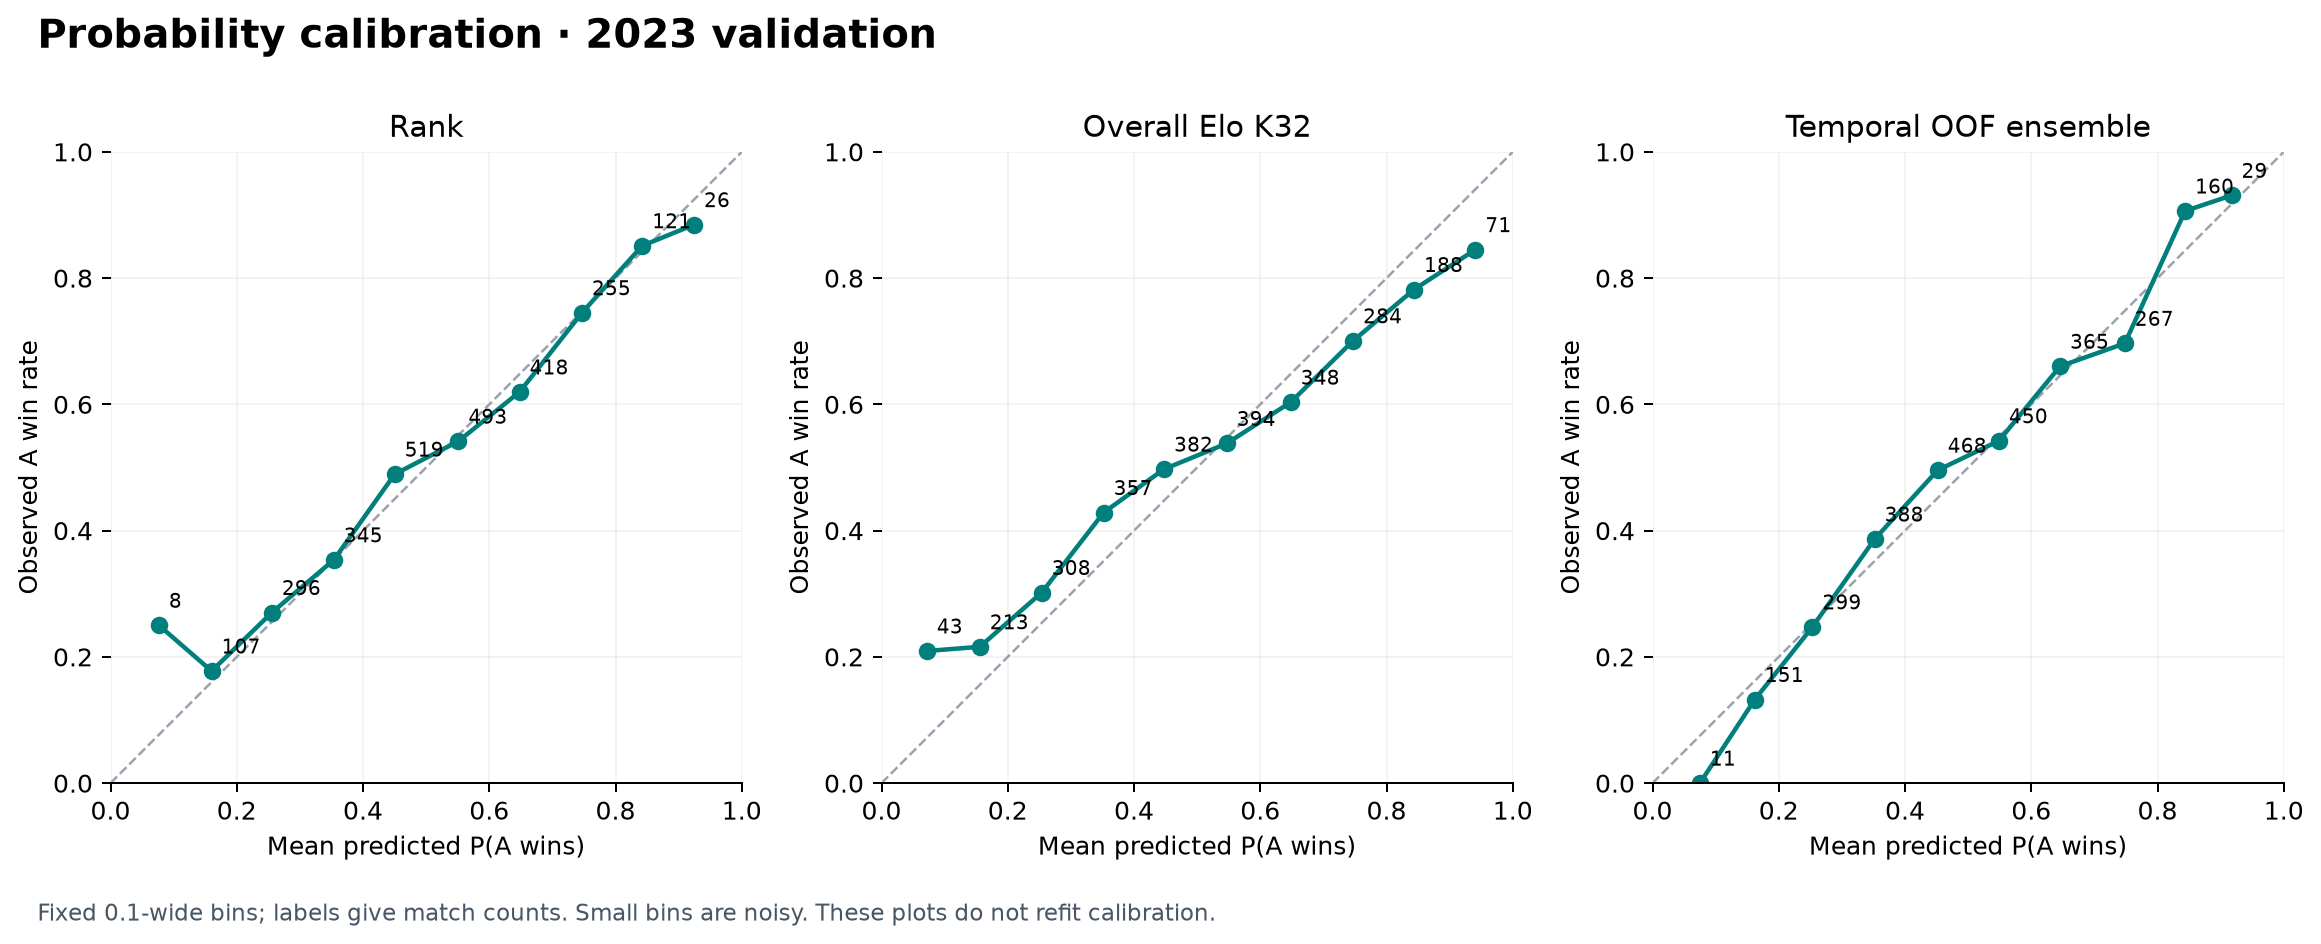

,group,model,matches,log_loss,accuracy,brier
0,All validation,lr_000_C0.1,2588,0.62980,0.63369,0.22016
1,All validation,oof_convex_ensemble,2588,0.61153,0.65070,0.21241
2,Hard,lr_000_C0.1,1442,0.63071,0.64147,0.22024
3,Hard,oof_convex_ensemble,1442,0.60547,0.65465,0.20985
4,Clay,lr_000_C0.1,830,0.63120,0.62048,0.22122
5,Clay,oof_convex_ensemble,830,0.62035,0.63253,0.21611
6,Grass,lr_000_C0.1,316,0.62196,0.63291,0.21697
7,Grass,oof_convex_ensemble,316,0.61605,0.68038,0.21435
8,Rank gap ≤ 10,lr_000_C0.1,326,0.67417,0.56748,0.24073
9,Rank gap ≤ 10,oof_convex_ensemble,326,0.64328,0.59816,0.22647


In [4]:
display(Image(filename=str(ROOT / 'results/modeling/calibration.png')))
display(subgroup_table(report))

## Worked match: Cincinnati final, 2023

Match `2023-422:55` has A = Carlos Alcaraz and B = Novak Djokovic. Its recorded tournament start date is 14 August 2023, so historical results stop at 24 July 2023. The actual final took place later in that tournament. The outcome is revealed here only to explain the saved validation prediction; it is never an input feature.

In [5]:
example_features, example_probabilities = worked_match(report)
display(example_features)
display(example_probabilities)

,match_id,tourney_date,player_a_name,player_b_name,rank_a,rank_b,log_rank_diff,overall_rate_diff,surface_rate_diff,h2h_rate_diff,a_won
1971,2023-422:55,2023-08-14,Carlos Alcaraz,Novak Djokovic,1,2,0.69315,0.025,-0.0818,0.2,0


,model,P(Alcaraz wins)
0,lr_000_C0.1,0.59608
1,lr_111_C0.1,0.58267
2,raw_elo_k32_diff,0.50465
3,oof_convex_ensemble,0.39221


## Reproduction and final-test handoff

From the repository root, use the locked modeling environment and run:

```bash
python -m scripts.train_models --with-serve
python -m scripts.model_report
```

The first command reruns training-period selection and 2023 scoring. The second renders saved results without fitting. `results/modeling/search_registry.json` records the candidate grid and source hashes; `frozen_selection.json` records the pre-2023 recommendation; `frozen_models.joblib` contains fitted estimators. `validation_predictions.csv` preserves every match-level probability.

The next teammate should independently reproduce the results, verify the Cincinnati cutoff and feature orientation, then explicitly unlock 2024–2025 for one frozen evaluation. Preserve the same population and T−21 rule, report 2024, 2025 and pooled metrics, and disclose any change before claiming final-test evidence. The current feature entry point deliberately rejects held-out targets.

Limitations: completed ranked Tour/major main draws only; no betting-market benchmark; tournament-week dates require conservative lag; repeated model selection limits validation inference. A stronger score here is not a cross-study SOTA comparison. See `docs/research/sota_evidence.md` for source-backed context.